# Práctica I — Aprendizaje Estadístico (2026/2027)

## Análisis de salud cardiometabólica con NHANES

**Dataset:** `data/nhanes_cardiometabolic_clean.csv` — National Health and Nutrition Examination Survey (CDC, EE. UU.).

**Estructura del trabajo:**

1. Selección del conjunto de datos
2. Exploración de los datos
3. Regresión lineal (simple y múltiple)
4. Selección y regularización: Ridge y Lasso
5. Análisis mediante PCA (y extensión PCR/PLS)
6. Regresión logística
7. Una única base de datos
8. Conclusiones

Se usa **una única base de datos**, ya que sus características permiten plantear razonablemente todos los problemas (regresión, regularización, reducción de dimensión y clasificación binaria).

> Este trabajo usa datos de salud de unas 10.700 personas (encuesta NHANES de EE. UU.) para contestar dos preguntas:
>
> 1. **Predecir un número** — ¿cuánto medirá la presión arterial de una persona? → esto se llama **regresión**.
> 2. **Predecir un sí/no** — ¿esta persona tiene hipertensión? → esto se llama **clasificación** (regresión logística).
>
> Para ello "enseñamos" a un modelo con una parte de los datos (**entrenar**) y comprobamos si acierta con otra parte que no ha visto (**probar**). 

## 1. Selección del conjunto de datos

Se ha elegido el dataset consolidado de **NHANES** (National Health and Nutrition Examination Survey, CDC), descargado directamente de <https://wwwn.cdc.gov/nchs/nhanes/> (dominio público). Reúne datos de **examen físico, cuestionarios y analíticas de laboratorio** de una muestra representativa de la población de EE. UU.

Es un dataset idóneo para esta práctica porque:
- contiene una respuesta cuantitativa natural (`sbp`, presión arterial sistólica) y otra binaria (`hypertension_dx`);
- tiene **muchos predictores numéricos correlacionados** (lípidos, hemograma, bioquímica), lo que motiva Ridge/Lasso y PCA;
- combina variables cuantitativas y cualitativas.

El script `get_data.py` genera el archivo `data/nhanes_cardiometabolic_clean.csv` (10.739 adultos de ≥ 20 años × 73 columnas con nombres legibles).

## 2. Exploración de los datos

>cuántas personas hay, qué variables tenemos, si faltan valores, cómo se distribuyen. Es como abrir una caja de herramientas y comprobar qué hay y en qué estado antes de ponerse a trabajar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
import statsmodels.api as sm

from scipy.stats import skew

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve)

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 6)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("data/nhanes_cardiometabolic_clean.csv")
print("Número de observaciones:", df.shape[0])
print("Número de variables:", df.shape[1])
df.head()

Número de observaciones: 10739
Número de variables: 73


,seqn,cycle,psu,strata,wt_mec,wt_fasting,fasting_subsample,age,sex,race_eth,...,baso_pct,rbc,hemoglobin,hematocrit,mcv,mch,mchc,rdw,platelets,mpv
0,83732,2015-2016,1,125,67814.753703,NaN,False,62,male,nh_white,...,0.5,4.93,15.2,44.7,90.8,30.8,34.0,13.9,181.0,8.3
1,83733,2015-2016,1,125,12641.212964,27361.171665,True,53,male,nh_white,...,1.8,4.89,17.5,49.7,101.8,35.8,35.1,13.4,170.0,9.6
2,83734,2015-2016,1,131,6287.919409,12735.546850,True,78,male,nh_white,...,0.9,4.18,12.4,37.9,90.8,29.6,32.6,14.7,223.0,9.0
3,83735,2015-2016,1,131,51039.317254,NaN,False,56,female,nh_white,...,0.9,4.54,12.8,40.1,88.3,28.2,31.9,13.1,280.0,9.1
4,83736,2015-2016,2,126,9117.368109,19089.755435,True,42,female,nh_black,...,0.2,4.16,12.1,36.5,87.8,29.1,33.2,12.3,275.0,7.7


### Descripción de las variables

Las variables se agrupan en los siguientes bloques (los nombres ya están "traducidos" desde los códigos originales del CDC):

| Grupo | Columnas |
|---|---|
| Diseño muestral | `seqn`, `cycle`, `psu`, `strata`, `wt_mec`, `wt_fasting`, `fasting_subsample` |
| Demografía | `age`, `sex`, `race_eth`, `education`, `income_poverty_ratio` |
| Exploración física | `sbp`, `dbp` (medias), `sbp1`, `dbp1`, `pulse`, `weight`, `height`, `bmi`, `waist` |
| Cuestionarios | `smoking`, `diabetes_dx`, `hypertension_dx`, `bp_meds`, `chol_meds` |
| Lípidos y glucosa | `total_chol`, `hdl`, `ldl`, `triglycerides`, `glucose_fasting`, `insulin`, `hba1c` |
| Inflamación | `hs_crp` |
| Hígado | `alt`, `ast`, `alp`, `ggt`, `ldh`, `bilirubin`, `albumin`, `total_protein`, `globulin` |
| Riñón | `creatinine`, `bun`, `uric_acid` |
| Electrolitos/minerales | `sodium`, `potassium`, `chloride`, `bicarbonate`, `calcium`, `phosphorus`, `iron`, `osmolality` |
| Bioquímica sin ayuno | `glucose_serum`, `chol_serum`, `trig_serum`, `cpk` |
| Hemograma | `wbc`, `lymph_pct`, `mono_pct`, `neut_pct`, `eos_pct`, `baso_pct`, `rbc`, `hemoglobin`, `hematocrit`, `mcv`, `mch`, `mchc`, `rdw`, `platelets`, `mpv` |

**¿Qué significa "en ayunas"?** Que la muestra de sangre se extrajo después de pasar al menos ~9 horas sin comer ni beber nada salvo agua (en la práctica, sin desayunar). Es necesario porque la glucosa, los triglicéridos y la insulina suben después de comer, y su valor dependería de cuándo y qué comió cada persona; en ayunas se mide el **nivel basal**, que es el que se usa en clínica (p. ej., una glucosa en ayunas ≥ 126 mg/dL indica diabetes). El LDL no se mide directamente, sino que se calcula a partir de los triglicéridos (fórmula de Friedewald), por lo que también requiere ayuno.

Las variables de la **submuestra en ayunas** (`ldl`, `triglycerides`, `glucose_fasting`, `insulin`) solo se midieron en la **sesión de mañana** (~4.500 adultos), ya que solo a esos participantes se les pidió acudir en ayunas. La columna `fasting_subsample` vale `True` cuando `wt_fasting > 0`, es decir, cuando la persona pertenece a esa submuestra. Para el resto, estas variables aparecen como `NaN`: no es un error, sino que no les correspondía la prueba.

Por contraste, la **bioquímica sin ayuno** (`glucose_serum`, `chol_serum`, `trig_serum`) se midió a todos los participantes, a cualquier hora del día: hay muchos más casos, pero los valores son más variables porque dependen de la última comida.

> **En resumen:** "en ayunas" = análisis hecho por la mañana sin haber comido. Da valores más fiables de azúcar y grasas en sangre, pero solo lo tiene ~4 de cada 10 personas del dataset.

### Variables cuantitativas y cualitativas

> - Una **variable cuantitativa** es un número (edad, peso, colesterol).
> - Una **variable cualitativa** es una etiqueta o categoría (sexo: hombre/mujer; diagnóstico: sí/no).
>
> En nuestra tabla, **cada fila es una persona** y **cada columna es una variable**.

In [3]:
categorical = df.select_dtypes(exclude=[np.number]).columns.tolist()  # texto y booleanas
quantitative = df.select_dtypes(include=[np.number]).columns.tolist()

print("Cualitativas (", len(categorical), "):", categorical)
print()
print("Cuantitativas (", len(quantitative), "). Primeras 20:", quantitative[:20])

Cualitativas ( 10 ): ['cycle', 'fasting_subsample', 'sex', 'race_eth', 'education', 'smoking', 'diabetes_dx', 'hypertension_dx', 'bp_meds', 'chol_meds']

Cuantitativas ( 63 ). Primeras 20: ['seqn', 'psu', 'strata', 'wt_mec', 'wt_fasting', 'age', 'income_poverty_ratio', 'sbp', 'sbp1', 'dbp', 'dbp1', 'pulse', 'weight', 'height', 'bmi', 'waist', 'total_chol', 'hdl', 'ldl', 'triglycerides']


In [4]:
# Resumen numérico de algunas variables relevantes
df[["age", "bmi", "sbp", "dbp", "total_chol", "hdl", "hba1c", "hs_crp"]].describe().round(2)

,age,bmi,sbp,dbp,total_chol,hdl,hba1c,hs_crp
count,10739.00,10581.00,10314.00,10287.00,10094.00,10094.00,10219.00,10042.00
mean,50.42,29.69,126.28,71.49,189.25,53.75,5.86,4.27
std,17.71,7.24,19.26,11.87,41.51,16.73,1.14,8.25
min,20.00,14.20,72.70,8.00,76.00,6.00,3.80,0.08
25%,35.00,24.70,112.70,64.00,161.00,42.00,5.30,0.83
50%,51.00,28.50,123.30,71.30,186.00,51.00,5.60,2.00
75%,65.00,33.40,136.00,78.70,214.00,63.00,6.00,4.60
max,80.00,86.20,238.00,138.70,545.00,226.00,17.00,188.50


### Visualizaciones relevantes

> La **correlación** mide si dos variables "se mueven juntas": si cuando una sube la otra también sube (correlación cercana a +1) o baja (cercana a −1). Un valor 0 = no hay relación aparente. En el mapa de calor de abajo, el rojo indica "van juntas" y el azul "van en sentido contrario".

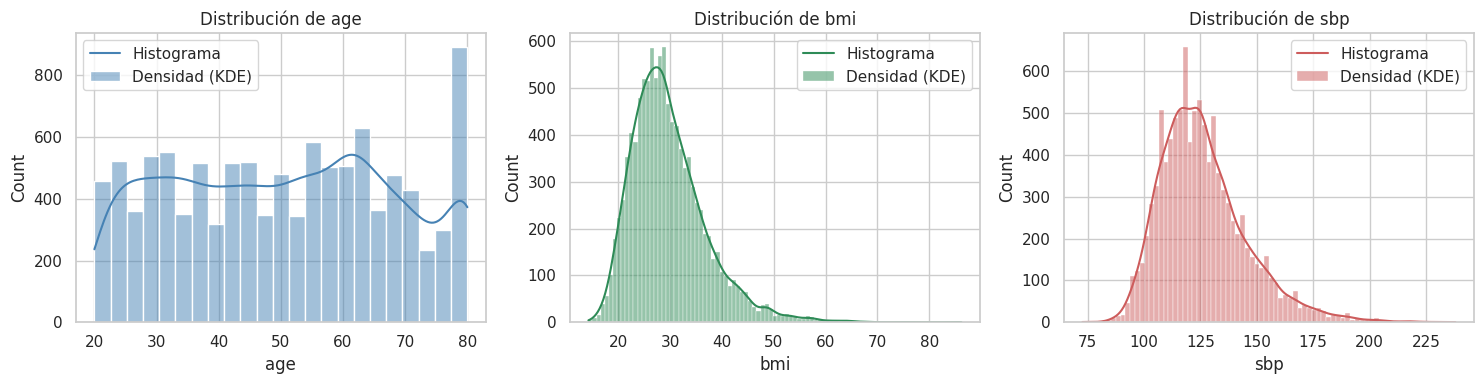

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var, color in zip(axes, ["age", "bmi", "sbp"], ["steelblue", "seagreen", "indianred"]):
    sns.histplot(data=df, x=var, kde=True, color=color, ax=ax)
    ax.set_title(f"Distribución de {var}")
    ax.legend(["Histograma", "Densidad (KDE)"])
plt.tight_layout()
plt.show()

Cada barra cuenta cuántas personas caen en un intervalo de valores; la forma de la "montaña" dice dónde se concentra la mayoría.

- **`age`:** va de 20 a 80 años, repartida de forma bastante uniforme, con un pico en 80 (el estudio "recorta" la edad ahí: todos los de 80 o más figuran como 80).
- **`bmi`:** asimétrica a la derecha: la mayoría está en valores normales/sobrepeso (mediana ≈ 28.5) y hay una cola de personas con IMC alto.
- **`sbp`:** forma de campana centrada en ~123 mmHg, con una cola hacia valores altos (los hipertensos).


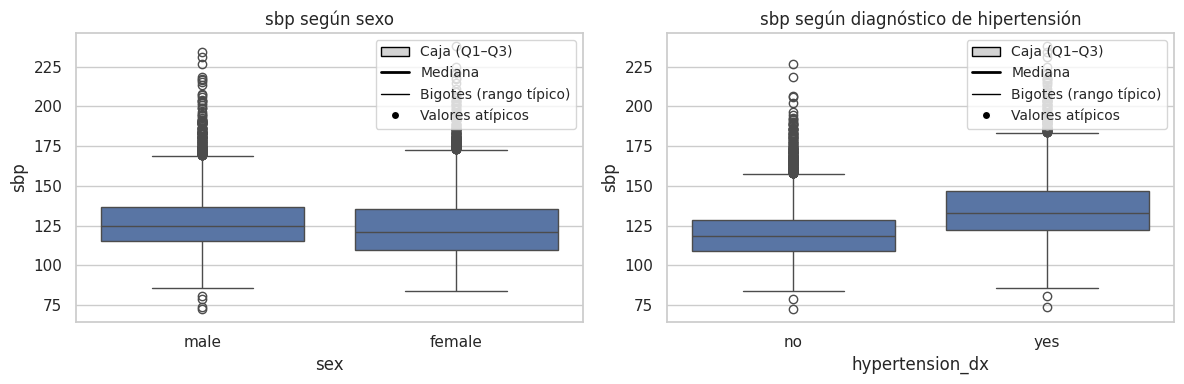

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="sex", y="sbp", ax=axes[0])
axes[0].set_title("sbp según sexo")
sns.boxplot(data=df, x="hypertension_dx", y="sbp", ax=axes[1])
axes[1].set_title("sbp según diagnóstico de hipertensión")

# Leyenda: qué representa cada parte del diagrama de caja
box_legend = [
    Patch(facecolor="lightgrey", edgecolor="black", label="Caja (Q1–Q3)"),
    Line2D([0], [0], color="black", lw=2, label="Mediana"),
    Line2D([0], [0], color="black", lw=1, label="Bigotes (rango típico)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
           markersize=6, label="Valores atípicos"),
]
axes[0].legend(handles=box_legend, fontsize="small", loc="upper right")
axes[1].legend(handles=box_legend, fontsize="small", loc="upper right")
plt.tight_layout()
plt.show()

La línea central es la **mediana** (el valor que deja la mitad por encima y la mitad por debajo); la caja contiene al 50 % central; los "bigotes" llegan hasta los valores típicos y los puntos sueltos son casos atípicos.

- **Izquierda (`sbp` por sexo):** los hombres tienen una mediana ligeramente mayor (≈ 124.7 mmHg) que las mujeres (≈ 121.3 mmHg).
- **Derecha (`sbp` por diagnóstico):** como cabe esperar, los diagnosticados de hipertensión tienen una `sbp` claramente más alta (mediana ≈ 132.7 frente a ≈ 118.7 mmHg); las cajas apenas se solapan.


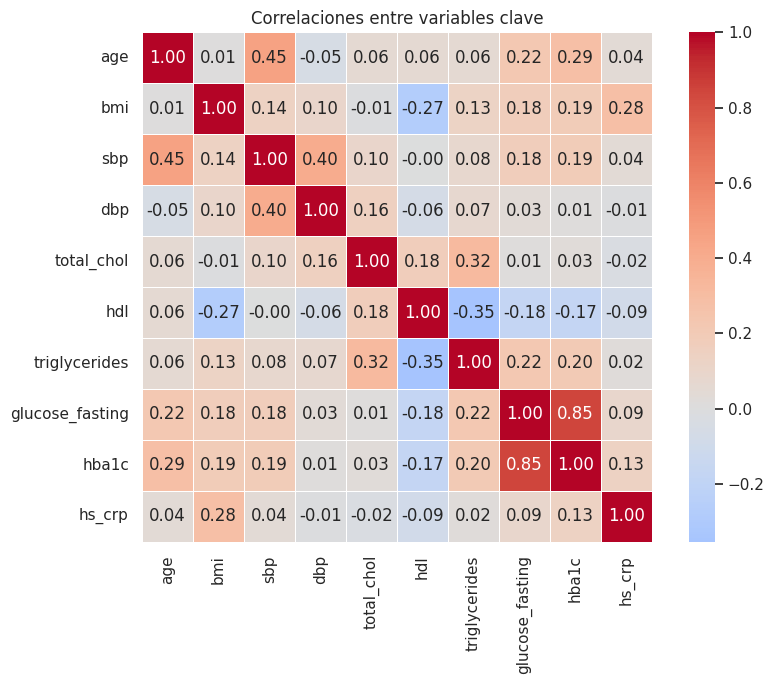

In [7]:
# Correlación entre biomarcadores clave (pairwise: ignora NA)
key = ["age", "bmi", "sbp", "dbp", "total_chol", "hdl", "triglycerides",
       "glucose_fasting", "hba1c", "hs_crp"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[key].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlaciones entre variables clave")
plt.tight_layout()
plt.show()

Cada casilla es la correlación entre dos variables (de −1 a +1). Rojo = van juntas; azul = van en sentido contrario; cerca de 0 (blanco) = sin relación.

- `glucose_fasting` y `hba1c` (r ≈ 0.85) miden casi lo mismo: el azúcar en sangre.
- `sbp` sube con la **edad** (r ≈ 0.45) y con `dbp` (r ≈ 0.40).
- `hdl` y `triglycerides` se mueven en sentido opuesto (r ≈ −0.35).

Que haya varias variables relacionadas entre sí es justo lo que motiva usar **Ridge/Lasso y PCA** más adelante.


### Valores ausentes

In [8]:
missing = df.isna().mean().sort_values(ascending=False)
print("Variables con mayor proporción de ausentes (%):")
print((missing.head(15) * 100).round(1).to_string())

print()
print("Observaciones sin ningún valor ausente:", df.dropna().shape[0], "de", df.shape[0])

Variables con mayor proporción de ausentes (%):
chol_meds               71.9
ldl                     57.2
triglycerides           56.7
insulin                 55.3
glucose_fasting         54.5
wt_fasting              52.1
income_poverty_ratio    11.8
dbp1                     9.2
sbp1                     8.6
ldh                      7.3
hs_crp                   6.5
ast                      6.4
waist                    6.4
cpk                      6.4
globulin                 6.3

Observaciones sin ningún valor ausente: 989 de 10739


**Discusión de los ausentes:**

- Las 4 variables de la **submuestra en ayunas** (`ldl`, `triglycerides`, `glucose_fasting`, `insulin`) tienen ~55 % de NA **por diseño**: solo se midieron en la sesión de mañana. No son "datos perdidos" en el sentido habitual, sino una subpoblación.
- `income_poverty_ratio` (~12 %) y algunas lecturas de presión (`sbp1`, `dbp1`) también presentan NA.
- Estrategia: en los modelos se trabaja con **casos completos** (`dropna`) sobre el subconjunto de variables elegido, y se evita incluir las variables de ayunas cuando no es necesario para conservar más observaciones. Se menciona como limitación el no imputar.

### Anomalías y aspectos relevantes

In [9]:
# 1) globulin es una combinación lineal exacta de total_protein y albumin
g = df[["globulin", "total_protein", "albumin"]].dropna()
print("globulin == total_protein - albumin :",
      np.allclose(g["globulin"], g["total_protein"] - g["albumin"]))

# 2) Asimetría de los biomarcadores
num_vars = ["age", "bmi", "sbp", "total_chol", "hdl", "triglycerides", "insulin",
            "hs_crp", "ggt", "alt", "cpk", "glucose_fasting"]
sk = pd.Series({c: skew(df[c].dropna()) for c in num_vars}).sort_values(ascending=False)
print()
print("Asimetría (skewness) de variables seleccionadas:")
print(sk.round(2).to_string())

globulin == total_protein - albumin : True

Asimetría (skewness) de variables seleccionadas:
cpk                20.58
ggt                12.66
triglycerides       9.09
insulin             8.51
hs_crp              8.22
alt                 4.58
glucose_fasting     3.87
hdl                 1.22
bmi                 1.20
sbp                 1.03
total_chol          0.73
age                 0.02


**Anomalías detectadas:**

- **Combinación lineal exacta:** `globulin = total_protein − albumin`. No debe incluirse junto a las otras dos en un modelo (hace singular la matriz de diseño).
- **Colas largas:** `triglycerides`, `insulin`, `hs_crp`, `ggt`, `alt`, `cpk` presentan asimetría fuerte (valores muy altos en pocos individuos). Se aplicará `log(1+x)` antes de estandarizar.
- **Multicolinealidad intencionada:** pares casi redundantes como `total_chol`–`chol_serum` (r≈0.99), `hemoglobin`–`hematocrit` (0.97), `sodium`–`osmolality` (0.81), `ast`–`alt` (0.73). Esto motiva el uso de Ridge/Lasso y PCA.
- **Medicación:** quien toma antihipertensivos (`bp_meds`) o estatinas (`chol_meds`) tiene la PA/colesterol tratados; es una limitación a tener en cuenta al interpretar.

## 3. Regresión lineal

> La **regresión** sirve para *predecir un número* a partir de otros datos. Imaginemos que queremos saber la presión arterial de alguien sabiendo su edad: dibujamos una nube de puntos (cada punto = una persona) y buscamos la **recta que mejor pasa por ellos**. Esa recta resume la relación, por ejemplo: "por cada año de edad, la presión sube ~0.49 puntos". **"Lineal"** solo quiere decir que la relación se dibuja con una recta (y no con una curva).

### 3.1 Variable respuesta y relación con los predictores

Se elige como **respuesta cuantitativa** la presión arterial sistólica `sbp` (mmHg). Es una variable continua, con interés clínico directo y disponible para la mayoría de individuos (solo ~4 % de NA).

> **Vocabulario:** llamamos **respuesta** (o "variable a predecir") a lo que queremos adivinar (aquí, la presión `sbp`), y **predictores** (o "variables explicativas") a los datos que usamos para adivinarlo (edad, IMC, colesterol…).

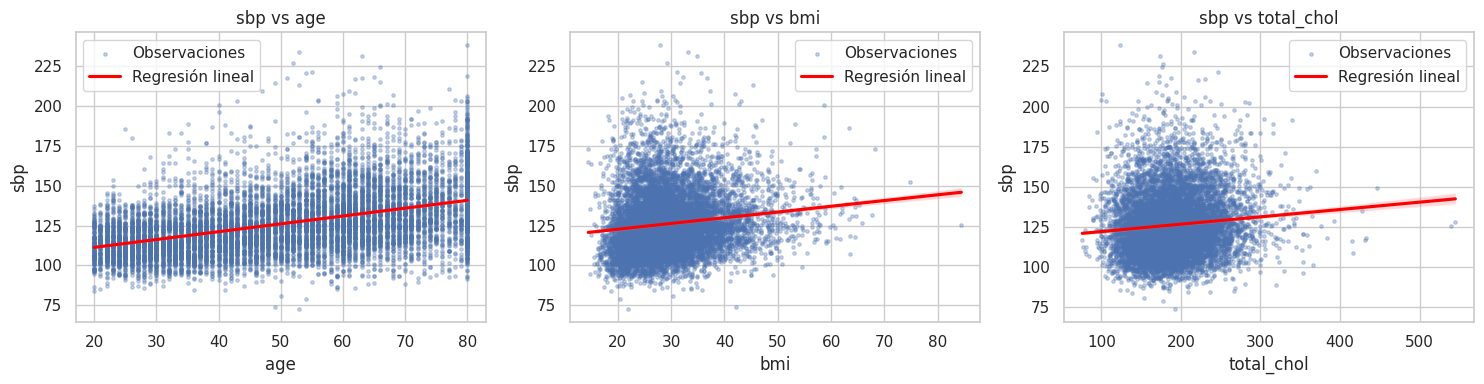

In [10]:
resp = "sbp"
# Relación gráfica de sbp con algunos predictores
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, ["age", "bmi", "total_chol"]):
    d = df[[resp, var]].dropna()
    sns.regplot(data=d, x=var, y=resp,
                scatter_kws={"s": 6, "alpha": 0.3}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"{resp} vs {var}")
    ax.collections[0].set_label("Observaciones")
    ax.lines[0].set_label("Regresión lineal")
    ax.legend()
plt.tight_layout()
plt.show()

cada punto es una persona y la línea roja es la recta de regresión (la tendencia media).

- **`sbp` vs `age`:** la presión sube claramente con la edad (línea ascendente).
- **`sbp` vs `bmi`:** también sube, pero con más dispersión (nube más "gorda").
- **`sbp` vs `total_chol`:** la línea es casi plana: apenas hay relación directa entre el colesterol total y la presión en esta muestra.


### 3.2 Regresión lineal simple (`sbp ~ age`)

La edad es el predictor más natural de la presión arterial. Ajustamos el modelo simple y lo interpretamos.

> Empezamos con la versión más simple posible: predecir la presión usando **solo la edad**. "Simple" = una única variable para predecir. Más adelante usaremos varias a la vez (regresión "múltiple").

In [11]:
d_simple = df[[resp, "age"]].dropna()
X_s = sm.add_constant(d_simple["age"])
model_simple = sm.OLS(d_simple[resp], X_s).fit()
print(model_simple.summary())

                            OLS Regression Results                            
Dep. Variable:                    sbp   R-squared:                       0.204
Model:                            OLS   Adj. R-squared:                  0.204
Method:                 Least Squares   F-statistic:                     2642.
Date:                Fri, 30 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:12:58   Log-Likelihood:                -43969.
No. Observations:               10314   AIC:                         8.794e+04
Df Residuals:                   10312   BIC:                         8.796e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        101.4229      0.512    197.973      0.0

**Interpretación del modelo simple:**

$$\widehat{sbp} = 101.42 + 0.492 \cdot age$$

- **Intercepto (101.42):** presión sistólica media estimada para `age = 0` (sin interpretación clínica directa).
- **Pendiente (0.492):** por cada año adicional de edad, la presión sistólica media aumenta ~0.49 mmHg (estadísticamente significativo, p ≈ 0).
- **Calidad del ajuste:** R² = 0.204, es decir, la edad por sí sola explica ~20 % de la variabilidad de `sbp`.

Con este modelo, una persona de 20 años tendría en media ≈ 111 mmHg y una de 80 ≈ 141 mmHg.

> **Traducción de los números:**
> - **Coeficiente 0.492** → "por cada año más de edad, la presión sube en promedio ~0.49 mmHg".
> - **R² = 0.204** → la edad, por sí sola, explica un 20 % de por qué unas personas tienen más presión que otras (el 80 % restante depende de otras cosas).
> - **"Estadísticamente significativo"** → es muy poco probable que esta relación sea fruto del azar; parece una pauta real.

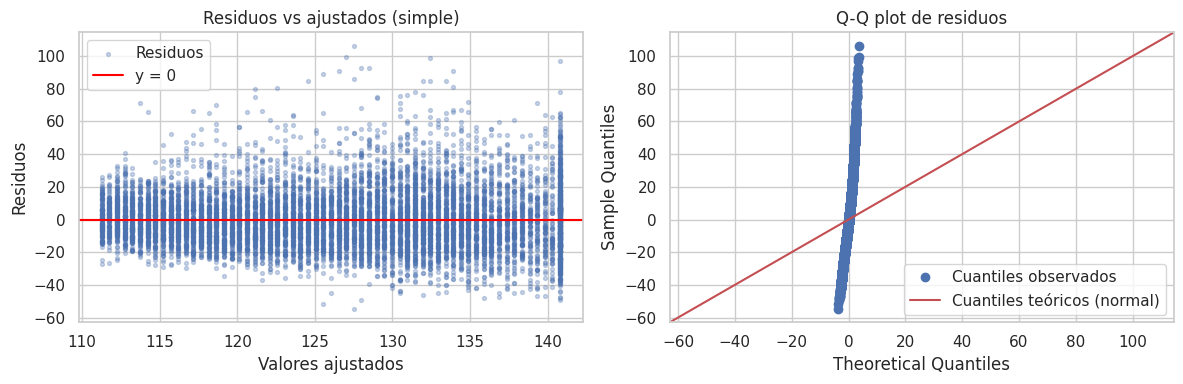

In [12]:
# Residuos del modelo simple
fitted = model_simple.fittedvalues
resid = model_simple.resid
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted, resid, s=8, alpha=0.3, label="Residuos")
axes[0].axhline(0, color="red", label="y = 0")
axes[0].set_xlabel("Valores ajustados"); axes[0].set_ylabel("Residuos")
axes[0].set_title("Residuos vs ajustados (simple)")
axes[0].legend()
sm.qqplot(resid, line="45", ax=axes[1])
axes[1].set_title("Q-Q plot de residuos")
axes[1].legend(["Cuantiles observados", "Cuantiles teóricos (normal)"])
plt.tight_layout()
plt.show()

los **residuos** son la diferencia entre la presión real y la predicha (el "error" de cada persona).

- **Izquierda (residuos vs ajustados):** si los puntos se reparten al azar en una banda horizontal alrededor de 0 (sin forma de embudo ni de curva), el modelo es razonable. Aquí se ve una banda más o menos constante.
- **Derecha (Q-Q plot):** compara la distribución de los residuos con una normal. Cuanto más pegados estén los puntos a la diagonal, más "normales" son los residuos (un supuesto habitual). Aquí se separan un poco en los extremos, algo normal con datos reales.


### 3.3 Regresión lineal múltiple

Añadimos `bmi`, `total_chol`, `hdl`, `sex` y `smoking`. No se incluyen todas las variables, sino las que se consideran más relevantes para explicar la presión arterial.

> Ahora usamos **varias** variables a la vez (edad, IMC, colesterol, HDL, sexo, tabaco) para predecir mejor. La idea clave es aislar: *"manteniendo todo lo demás igual, ¿cuánto cambia la presión si solo cambia esta variable?"*.

In [13]:
cols = [resp, "age", "bmi", "total_chol", "hdl", "sex", "smoking"]
d_multi = df[cols].dropna()
d_multi = pd.get_dummies(d_multi, columns=["sex", "smoking"], drop_first=True)

y_m = d_multi[resp]
X_m = d_multi.drop(columns=resp)
X_m_const = sm.add_constant(X_m)

model_multi = sm.OLS(y_m, X_m_const).fit()
print(model_multi.summary())

                            OLS Regression Results                            
Dep. Variable:                    sbp   R-squared:                       0.236
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                     423.5
Date:                Fri, 30 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:12:59   Log-Likelihood:                -40657.
No. Observations:                9620   AIC:                         8.133e+04
Df Residuals:                    9612   BIC:                         8.139e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             81.8482      1.433     57.

**Interpretación del modelo múltiple** (R² = 0.236, n = 9.620):

- **`age` (+0.488):** el predictor más relevante; ~0.49 mmHg más de `sbp` por año, manteniendo el resto constante.
- **`bmi` (+0.394):** ~0.39 mmHg más por cada unidad de IMC.
- **`total_chol` (+0.034) y `hdl` (+0.018):** efectos pequeños; el colesterol apenas desplaza la PA en esta muestra.
- **`sex_male` (+3.09):** los hombres tienen en media ~3 mmHg más que las mujeres, a igualdad del resto de variables.
- **`smoking_former` (−2.14) / `smoking_never` (−0.85):** respecto a los fumadores actuales (categoría de referencia).

**Comparación simple vs múltiple:** el R² pasa de 0.204 a 0.236. La edad apenas cambia su coeficiente (0.492 → 0.488), lo que indica que no estaba "absorbiendo" el efecto de las otras variables. El resto de predictores añaden poca capacidad explicativa adicional.

> **Cómo leerlo:** "manteniendo el resto constante" es fundamental: es como comparar a dos personas idénticas salvo en un detalle, para ver el efecto de ese detalle. El R² sube un poco (0.204 → 0.236), es decir, añadir variables ayuda, pero la edad sigue siendo la que más pesa.

### 3.4 Predicciones para nuevas observaciones

In [14]:
# Nueva observación: mujer, 55 años, IMC 28, colesterol total 200, HDL 55, no fumadora
nueva = pd.DataFrame([{"age": 55, "bmi": 28, "total_chol": 200, "hdl": 55,
                       "sex_male": 0, "smoking_former": 0, "smoking_never": 1}])[X_m.columns]
pred_nueva = model_multi.predict(sm.add_constant(nueva, has_constant="add"))[0]
print(f"Predicción de sbp para la nueva observación: {pred_nueva:.1f} mmHg")

# Intervalos al 95 %: de confianza (para la media de personas con ese perfil)
# y de predicción (para una persona concreta, incluye la variabilidad individual)
pred_int = model_multi.get_prediction(sm.add_constant(nueva, has_constant="add")).summary_frame(alpha=0.05)
print(f"IC 95 % (media):      [{pred_int['mean_ci_lower'][0]:.1f}, {pred_int['mean_ci_upper'][0]:.1f}] mmHg")
print(f"IP 95 % (individuo):  [{pred_int['obs_ci_lower'][0]:.1f}, {pred_int['obs_ci_upper'][0]:.1f}] mmHg")

Predicción de sbp para la nueva observación: 126.7 mmHg
IC 95 % (media):      [126.1, 127.2] mmHg
IP 95 % (individuo):  [94.2, 159.2] mmHg


**Interpretación de los intervalos:** el **intervalo de confianza** es estrecho porque estima la presión *media* de todas las personas con ese perfil, y con ~9.600 observaciones esa media se conoce con mucha precisión. El **intervalo de predicción** es mucho más ancho porque se refiere a *una persona concreta*: añade la variabilidad individual que el modelo no explica (R² ≈ 0.24). Es decir, el modelo describe bien la tendencia media, pero predice con bastante incertidumbre la presión de un individuo.

In [ ]:
# Evaluación predictiva simple vs múltiple (train/test)
#  Enseñamos con el 80 % (entrenamiento) y comprobamos con el 20 % que el
#    modelo NO ha visto (test). Así medimos si generaliza a gente nueva y no
#    se ha aprendido los datos de memoria.
#    - MSE: error medio de las predicciones (cuanto más bajo, mejor).
#    - R²: proporción de la variación de sbp que explica el modelo.

X_tr, X_te, y_tr, y_te = train_test_split(
    X_m_const, y_m, test_size=0.2, random_state=RANDOM_STATE)

ols_simple = sm.OLS(y_tr, X_tr[["const", "age"]]).fit()
ols_multi = sm.OLS(y_tr, X_tr).fit()

for name, model, cols_use in [("Simple", ols_simple, ["const", "age"]),
                              ("Múltiple", ols_multi, X_tr.columns)]:
    pred = model.predict(X_te[cols_use])
    print(f"{name:9s} -> MSE test = {mean_squared_error(y_te, pred):.1f} | "
          f"R² test = {r2_score(y_te, pred):.3f}")

Simple    -> MSE test = 297.3 | R² test = 0.217
Múltiple  -> MSE test = 289.0 | R² test = 0.239


## 4. Selección y regularización: Ridge y Lasso

### ¿Por qué regularizar?

El panel de biomarcadores tiene **multicolinealidad importante** (pares casi redundantes y una combinación lineal exacta, `globulin`). En presencia de colinealidad:

- los coeficientes de OLS son **inestables** (cambian mucho ante pequeñas variaciones de los datos);
- la varianza de los estimadores es alta.

La regularización (Ridge = penalización L2, Lasso = L1) encoge los coeficientes hacia cero, reduce la varianza y, en Lasso, **selecciona variables** poniendo coeficientes exactamente a cero.

**Aviso de fuga de información:** el escalado se incluye dentro de un `Pipeline`, de modo que en cada fold de la validación cruzada el `StandardScaler` se reajusta solo con los datos de entrenamiento.

> Cuando muchas variables se parecen entre sí (como el colesterol total y el colesterol en suero, que son casi lo mismo), el modelo se confunde: reparte la "explicación" entre ellas y se vuelve inestable. **Regularizar** = poner un pequeño "freno" para que el modelo no se complique de más. Hay dos frenos famosos:
>
> - **Ridge:** encoge los coeficientes un poco (los acerca a cero) pero no los elimina.
> - **Lasso:** además de encogerlos, puede dejarlos exactamente en **cero**, es decir, "olvidarse" de algunas variables.
>
> **Validación cruzada y α (alpha):** el freno tiene un botón de intensidad llamado **α**. Con α = 0 no hay freno; con α enorme frenamos tanto que el modelo queda casi a cero. Para elegir la intensidad correcta usamos **validación cruzada**: dividimos los datos de entrenamiento en 10 trozos, entrenamos en 9 y comprobamos en el trozo que dejamos fuera, rotando. Así elegimos el α que mejor funciona "en general", no solo en un trozo concreto.

In [ ]:
# Panel numérico "sin ayunas" (sin las 4 variables de la submuestra en ayunas ni globulin)
#  Elegimos 46 medidas de sangre/cuerpo disponibles para casi todas las personas.
panel = [
    "age", "bmi", "waist", "pulse",
    "total_chol", "hdl", "hba1c", "hs_crp",
    "albumin", "total_protein",
    "alt", "ast", "alp", "ggt", "ldh", "bilirubin", "cpk",
    "bun", "creatinine", "uric_acid",
    "sodium", "potassium", "chloride", "bicarbonate",
    "calcium", "phosphorus", "iron", "osmolality",
    "glucose_serum", "chol_serum", "trig_serum",
    "wbc", "rbc", "hemoglobin", "hematocrit", "mcv", "mch", "mchc", "rdw",
    "platelets", "mpv",
    "lymph_pct", "mono_pct", "neut_pct", "eos_pct", "baso_pct",
]
skewed = ["hs_crp", "ggt", "alt", "cpk", "trig_serum"]

data_pen = df[panel + ["sbp"]].copy()
for c in skewed:
    data_pen[c] = np.log1p(data_pen[c])
data_pen = data_pen.dropna()

X_pen = data_pen[panel]
y_pen = data_pen["sbp"]
print("Casos completos para Ridge/Lasso/PCA:", X_pen.shape)

Casos completos para Ridge/Lasso/PCA: (9075, 46)


In [ ]:
#  Separamos 80 % (entrenar) / 20 % (test). El test NO se toca hasta el final.
X_train, X_test, y_train, y_test = train_test_split(
    X_pen, y_pen, test_size=0.2, random_state=RANDOM_STATE)
print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)

#  Validación cruzada: para elegir el mejor alpha, dividimos el entrenamiento
#    en 10 trozos, entrenamos en 9 y validamos en el que queda fuera (rotando).
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

Entrenamiento: (7260, 46) | Test: (1815, 46)


In [18]:
# Modelo de referencia OLS
ols_pipe = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
ols_pipe.fit(X_train, y_train)
pred_ols = ols_pipe.predict(X_test)
print(f"OLS -> MSE test = {mean_squared_error(y_test, pred_ols):.1f} | "
      f"R² test = {r2_score(y_test, pred_ols):.3f}")

OLS -> MSE test = 236.5 | R² test = 0.281


In [19]:
alphas = np.logspace(-3, 5, 100)

ridge_pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge())])
ridge_search = GridSearchCV(ridge_pipe, {"model__alpha": alphas},
                            scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
ridge_search.fit(X_train, y_train)
print("Ridge: mejor alpha =", ridge_search.best_params_["model__alpha"],
      "| MSE CV =", round(-ridge_search.best_score_, 1))

Ridge: mejor alpha = 148.49682622544665 | MSE CV = 264.6


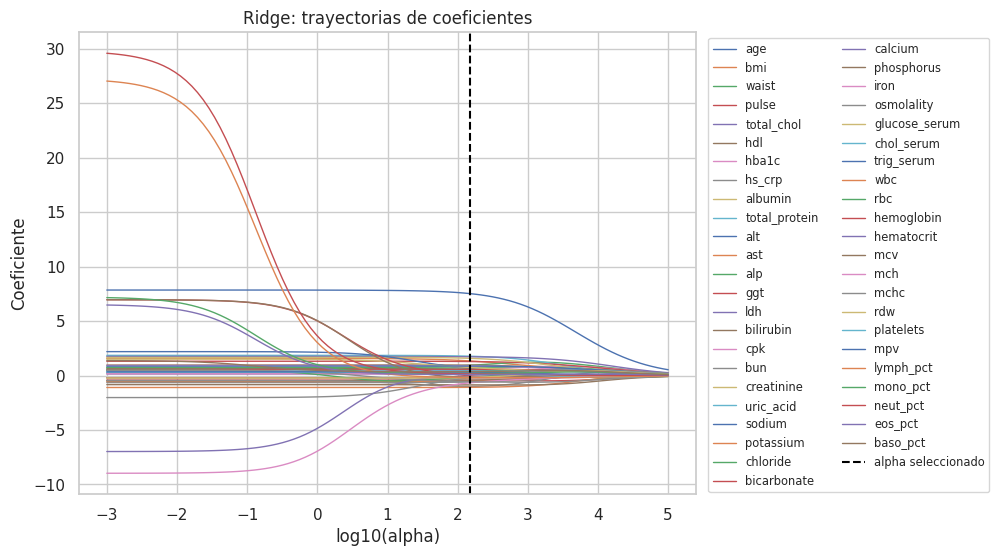

In [20]:
# Trayectoria de coeficientes Ridge
scaler_path = StandardScaler().fit(X_train)
X_train_scaled = scaler_path.transform(X_train)

ridge_coefs = np.asarray([Ridge(alpha=a).fit(X_train_scaled, y_train).coef_ for a in alphas])
plt.figure(figsize=(13, 6))
for j, name in enumerate(X_pen.columns):
    plt.plot(np.log10(alphas), ridge_coefs[:, j], lw=1, label=name)
plt.axvline(np.log10(ridge_search.best_params_["model__alpha"]), color="black",
            linestyle="--", label="alpha seleccionado")
plt.xlabel("log10(alpha)"); plt.ylabel("Coeficiente")
plt.title("Ridge: trayectorias de coeficientes")
plt.legend(bbox_to_anchor=(1.01, 1.0), loc="upper left", fontsize="x-small", ncol=2)
plt.subplots_adjust(right=0.60)
plt.show()

Cada línea es el coeficiente de una variable a medida que aumenta α (la intensidad del "freno"). Con α pequeño (izquierda) los coeficientes están repartidos; al aumentar α se **encogen hacia 0** (Ridge los acerca a cero, pero no llega a anularlos). La línea discontinua marca el α elegido por validación cruzada.


In [21]:
lasso_pipe = Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=20000))])
lasso_search = GridSearchCV(lasso_pipe, {"model__alpha": alphas},
                            scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
lasso_search.fit(X_train, y_train)
print("Lasso: mejor alpha =", lasso_search.best_params_["model__alpha"],
      "| MSE CV =", round(-lasso_search.best_score_, 1))

Lasso: mejor alpha = 0.02848035868435802 | MSE CV = 264.6


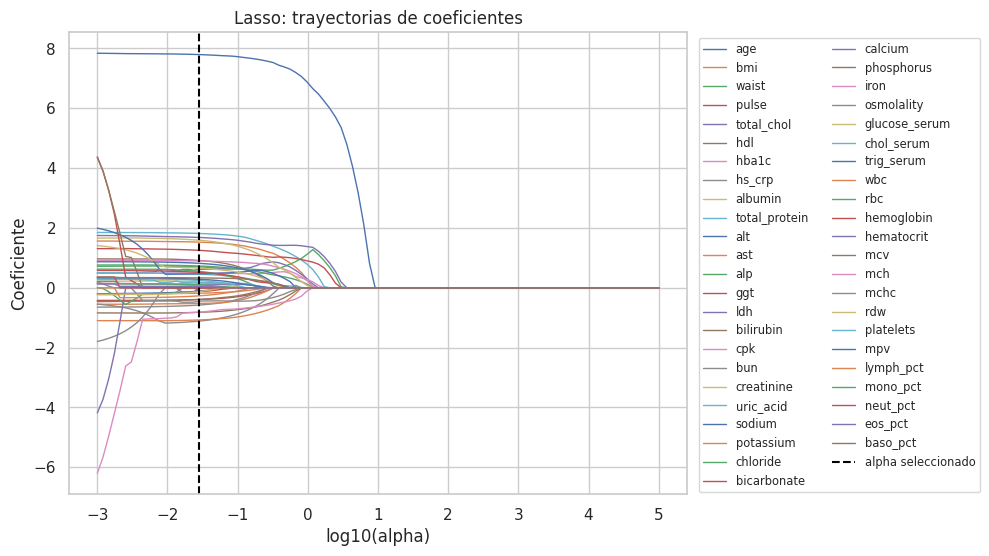

In [22]:
# Trayectoria de coeficientes Lasso
lasso_coefs = np.asarray([Lasso(alpha=a, max_iter=20000).fit(X_train_scaled, y_train).coef_ for a in alphas])
plt.figure(figsize=(13, 6))
for j, name in enumerate(X_pen.columns):
    plt.plot(np.log10(alphas), lasso_coefs[:, j], lw=1, label=name)
plt.axvline(np.log10(lasso_search.best_params_["model__alpha"]), color="black",
            linestyle="--", label="alpha seleccionado")
plt.xlabel("log10(alpha)"); plt.ylabel("Coeficiente")
plt.title("Lasso: trayectorias de coeficientes")
plt.legend(bbox_to_anchor=(1.01, 1.0), loc="upper left", fontsize="x-small", ncol=2)
plt.subplots_adjust(right=0.60)
plt.show()

Igual que el de Ridge, pero aquí, al crecer α, muchas líneas **caen exactamente a 0** y desaparecen del gráfico: eso es Lasso "descartando" variables. Las pocas líneas que aguantan (como `age`, la más alta) son las que más aportan a la predicción. La línea discontinua marca el α elegido.


In [23]:
# Variables que conserva Lasso
lasso_model = lasso_search.best_estimator_.named_steps["model"]
lasso_coef = pd.Series(lasso_model.coef_, index=X_pen.columns)
keep = lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False)
print("Nº de coeficientes no nulos:", (lasso_coef != 0).sum(), "de", len(lasso_coef))
print()
print(keep.round(3).to_string())

Nº de coeficientes no nulos: 42 de 46

age              7.795
total_protein    1.816
ldh              1.683
creatinine       1.590
bmi              1.526
ggt              1.252
bun             -1.112
potassium       -1.073
hdl              0.913
cpk              0.898
phosphorus      -0.818
trig_serum       0.818
mch             -0.812
alp              0.729
waist            0.696
glucose_serum    0.657
total_chol       0.616
hs_crp          -0.575
chloride         0.549
ast             -0.522
bicarbonate      0.515
hba1c            0.495
sodium           0.467
uric_acid        0.456
mchc            -0.446
pulse           -0.390
bilirubin       -0.389
baso_pct         0.331
mpv              0.286
lymph_pct       -0.268
platelets        0.243
albumin          0.188
wbc             -0.180
chol_serum       0.170
rdw             -0.126
calcium          0.123
alt             -0.109
hemoglobin      -0.108
mono_pct         0.096
iron             0.069
eos_pct          0.038
hematocrit      -0

**Interpretación de la selección de Lasso:** con el α óptimo (muy pequeño, ≈ 0.028), Lasso conserva **42 de 46** coeficientes, es decir, la **selección de variables es limitada**. La señal está dominada por pocas variables (`age`, coeficiente ≈ 7.8 en escala estandarizada, seguida de `total_protein`, `ldh`, `creatinine`, `bmi`, `ggt`), así que apenas necesita regularización. Las 4 variables que **anula** son miembros de grupos redundantes: `osmolality` (muy correlacionada con `sodium`), `rbc` y `mcv` (correlacionadas con el resto del hemograma) y `neut_pct` (complementaria del resto de porcentajes leucocitarios, que suman 100). Tres matices importantes: (1) que un coeficiente sea cero **no** demuestra que la variable no tenga relación con la respuesta, pues puede estar "representada" por otra variable correlacionada; (2) Lasso selecciona predictores en función de la penalización y de las correlaciones, por lo que **no demuestra efectos independientes ni causalidad**; (3) un coeficiente grande **no** equivale a una mayor importancia en sentido absoluto: su magnitud depende de la escala, de la penalización y de las demás variables incluidas en el modelo (aquí `age` domina porque su asociación con `sbp` es fuerte y consistente, no porque su coeficiente sea "grande" por sí mismo).

In [24]:
# Comparación final en test: OLS, Ridge, Lasso y (opcional) Elastic Net
elastic_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", ElasticNet(max_iter=10000))]),
    {"model__alpha": np.logspace(-3, 3, 20), "model__l1_ratio": [0.5, 0.9, 0.99, 1.0]},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
elastic_search.fit(X_train, y_train)

models = {
    "OLS": ols_pipe,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_,
    "Elastic Net": elastic_search.best_estimator_,
}
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({"Modelo": name,
                    "MSE test": mean_squared_error(y_test, pred),
                    "R² test": r2_score(y_test, pred)})
display(pd.DataFrame(results).sort_values("MSE test").round(3))

,Modelo,MSE test,R² test
2,Lasso,235.623,0.283
3,Elastic Net,235.919,0.282
1,Ridge,236.099,0.282
0,OLS,236.519,0.281


**Conclusión de la sección:** en este problema, con una señal dominada por `age` y `bmi`, la regularización **no mejora de forma apreciable a OLS** en test (MSE ≈ 236.5 para OLS frente a ≈ 235.6–236.1 para Ridge/Lasso). Una diferencia de ~1 punto de MSE sobre una respuesta con desviación típica ≈ 18 mmHg es pequeña y está dentro del ruido de muestreo de una única partición de test, por lo que **no cabe afirmar que un modelo sea claramente superior**. El valor de Lasso aquí es sobre todo de **estabilidad** ante la colinealidad; su capacidad de **selección** es limitada (conserva 42 de 46 variables) y **no** debe leerse como identificación de efectos independientes ni de relaciones causales. La comparación de la celda anterior usa el conjunto de test **una única vez** (evaluación final); los hiperparámetros (α) se eligieron exclusivamente por validación cruzada.

## 5. Análisis mediante PCA

Aplicamos PCA al **mismo panel cuantitativo** de la sección anterior (tras `log(1+x)` de las asimétricas). Es un análisis **no supervisado** (no interviene la respuesta `sbp`): sirve para resumir los 46 biomarcadores correlacionados en un número menor de componentes.

**Nota sobre los datos usados:** aquí PCA se ajusta sobre el **panel completo de casos completos** (n = 9.075), mientras que en la sección 4 se reservó un 20 % de test. No es una incoherencia: el PCA es **exploratorio y no supervisado**, de modo que describe la estructura del conjunto disponible; las evaluaciones *predictivas* basadas en componentes (PCR/PLS, más abajo) sí se hacen por separado mediante `Pipeline` + validación cruzada, sin tocar el test. Además, como todo el análisis usa **casos completos**, el número de observaciones varía según los predictores incluidos.

Recordatorio: `PCA` de sklearn **solo centra** (no escala); por eso estandarizamos antes con `StandardScaler`.

> El **PCA** es una forma de *resumir*. Tenemos 46 medidas que a menudo cuentan cosas parecidas (p. ej., hemoglobina y hematocrito van de la mano). El PCA las mezcla y crea unas pocas **componentes**: "resúmenes" nuevos, independientes entre sí, ordenados del que más información conserva al que menos. Así, en vez de mirar 46 números, miramos unos pocos "mega-indicadores".

In [ ]:
#  Primero ponemos todas las variables en la misma escala (media 0, desviación 1),
#    para que ninguna "pese" más solo por tener números más grandes.
X_scaled = StandardScaler().fit_transform(X_pen)
pca = PCA()
Z = pca.fit_transform(X_scaled)

loadings = pca.components_          # filas = componentes (direcciones )
var = pca.explained_variance_       # varianza de cada Zj
ratio = pca.explained_variance_ratio_

print("Resumen del modelo PCA (varianza explicada):")
summary_pca = pd.DataFrame({
    "Desv. típica": np.sqrt(var),
    "Varianza": var,
    "Proporción": ratio,
    "Acumulada": np.cumsum(ratio),
}, index=[f"PC{i+1}" for i in range(len(var))])
display(summary_pca.head(10).round(3))

# ¿Cuántas componentes hacen falta para alcanzar distintos niveles de varianza?
print()
for thr in [0.7, 0.8, 0.9]:
    k = int(np.searchsorted(np.cumsum(ratio), thr) + 1)
    print(f"  {int(thr*100)}% de varianza -> {k} componentes")

Resumen del modelo PCA (varianza explicada):


,Desv. típica,Varianza,Proporción,Acumulada
PC1,2.227,4.961,0.108,0.108
PC2,2.041,4.168,0.091,0.198
PC3,1.820,3.312,0.072,0.270
PC4,1.605,2.577,0.056,0.326
PC5,1.565,2.450,0.053,0.380
PC6,1.421,2.018,0.044,0.424
PC7,1.412,1.993,0.043,0.467
PC8,1.318,1.737,0.038,0.505
PC9,1.275,1.625,0.035,0.540
PC10,1.243,1.546,0.034,0.574



  70% de varianza -> 15 componentes
  80% de varianza -> 20 componentes
  90% de varianza -> 27 componentes


In [26]:
# Verificación: explained_variance_ == valores singulares^2 / (n-1)
U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)
print("¿explained_variance_ == S²/(n-1)?", np.allclose(var, S**2 / (len(X_scaled) - 1)))

# Justificación de la desviación típica de la primera componente
print()
print("Desviación típica de PC1:", round(np.sqrt(var[0]), 3))
print("Varianza total (suma autovalores):", round(var.sum(), 2), "= nº de variables:", X_pen.shape[1])

¿explained_variance_ == S²/(n-1)? True

Desviación típica de PC1: 2.227
Varianza total (suma autovalores): 46.01 = nº de variables: 46


**Justificación de la desviación típica de PC1:** al estar las variables estandarizadas, cada una tiene varianza 1 y la varianza total es `p` (el nº de variables, 46). La varianza de `Z1` es el primer autovalor y su desviación típica es su raíz cuadrada (≈ 2.23). Un autovalor ≫ 1 significa que PC1 concentra bastante más variabilidad que una sola variable original.

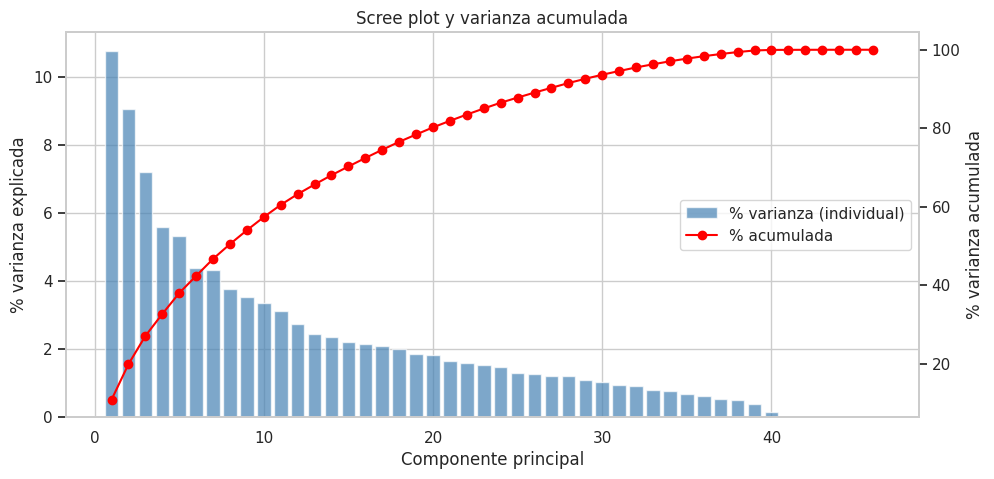

In [27]:
# Scree plot y varianza acumulada
fig, ax1 = plt.subplots(figsize=(11, 5))
comp_idx = np.arange(1, len(var) + 1)
ax1.bar(comp_idx, ratio * 100, color="steelblue", alpha=0.7, label="% varianza (individual)")
ax1.set_xlabel("Componente principal"); ax1.set_ylabel("% varianza explicada")

ax2 = ax1.twinx()
ax2.plot(comp_idx, np.cumsum(ratio) * 100, color="red", marker="o", label="% acumulada")
ax2.set_ylabel("% varianza acumulada")
ax2.grid(False)

l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lb1 + lb2, loc="center right")
plt.title("Scree plot y varianza acumulada")
plt.show()

las barras indican qué porcentaje de la información total conserva cada componente (la primera es la más informativa) y la línea roja es la suma acumulada. La caída es **gradual**: la primera componente solo explica ~11 %, y hay que sumar ~15 para llegar al 70 % y ~20 para el 80 %. Por eso decimos que la reducción de dimensión es real pero "moderada".


In [28]:
loadings_df = pd.DataFrame(loadings.T, index=X_pen.columns,
                           columns=[f"PC{i+1}" for i in range(X_pen.shape[1])])
for pc in ["PC1", "PC2", "PC3"]:
    top = loadings_df[pc].reindex(loadings_df[pc].abs().sort_values(ascending=False).index).head(6)
    print(f"{pc} — variables con mayor |peso|:")
    print(top.round(3).to_string())
    print()

PC1 — variables con mayor |peso|:
hemoglobin    0.383
hematocrit    0.351
mch           0.287
rdw          -0.277
mchc          0.274
iron          0.269

PC2 — variables con mayor |peso|:
waist         0.358
bmi           0.316
hs_crp        0.265
hba1c         0.262
trig_serum    0.252
ggt           0.248

PC3 — variables con mayor |peso|:
osmolality    0.359
age           0.293
bun           0.287
sodium        0.262
mcv           0.257
rbc          -0.254



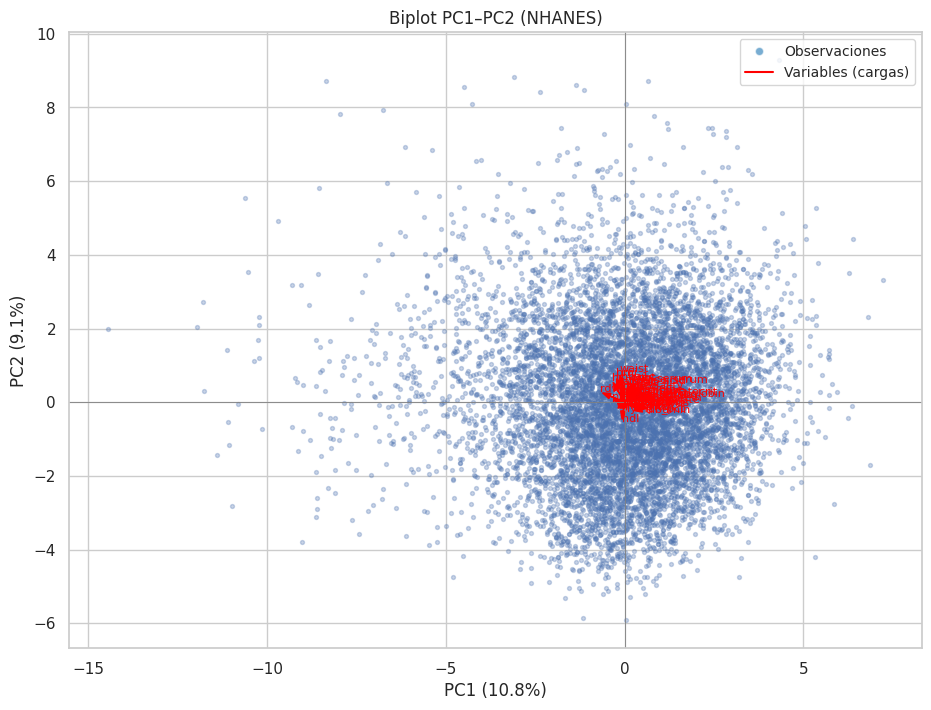

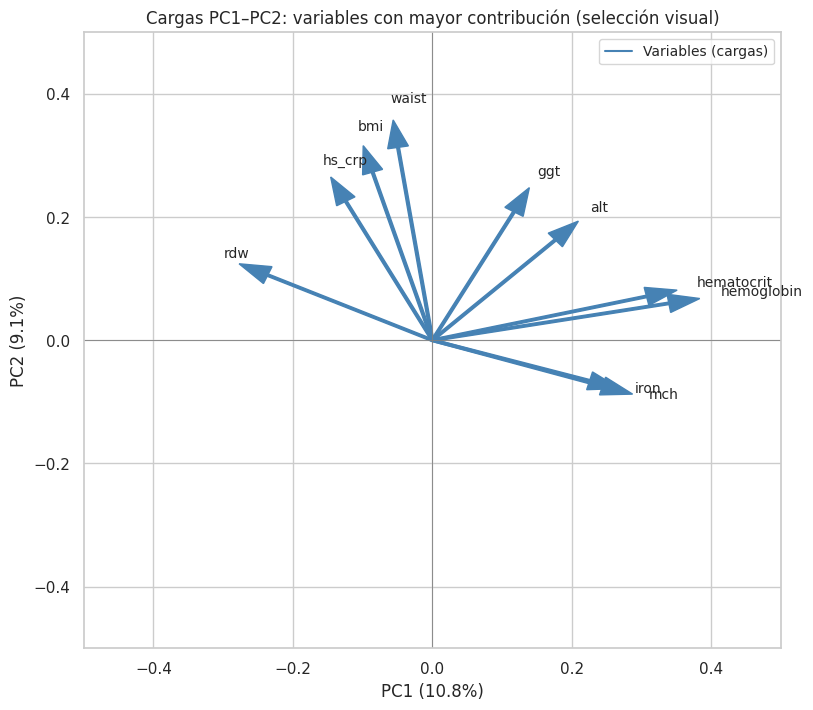

In [29]:
# Biplot PC1-PC2
comp = pca.components_.T * np.sqrt(pca.explained_variance_)
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(Z[:, 0], Z[:, 1], s=8, alpha=0.3)
for j, name in enumerate(X_pen.columns):
    ax.arrow(0, 0, comp[j, 0], comp[j, 1], color="red", width=0.002,
             head_width=0.15, length_includes_head=True)
    ax.text(comp[j, 0] * 1.12, comp[j, 1] * 1.12, name, color="red", fontsize=8)
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel(f"PC1 ({ratio[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({ratio[1]*100:.1f}%)")
ax.set_title("Biplot PC1–PC2 (NHANES)")

# Leyenda: qué representa cada elemento del biplot
biplot_legend = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#1f77b4",
           markersize=6, alpha=0.6, label="Observaciones"),
    Line2D([0], [0], color="red", lw=1.5, label="Variables (cargas)"),
]
ax.legend(handles=biplot_legend, fontsize="small", loc="upper right")
plt.show()

# Lectura alternativa: solo las variables con mayor contribución a PC1–PC2
# (selección visual de las ~10 con mayor norma de cargas en el plano PC1–PC2).
contrib = np.sqrt(loadings[0, :] ** 2 + loadings[1, :] ** 2)
top_idx = np.argsort(contrib)[::-1][:10]

fig, ax = plt.subplots(figsize=(9, 8))
for j in top_idx:
    x = loadings[0, j]
    y = loadings[1, j]
    ax.arrow(0, 0, x, y, color="steelblue", width=0.004,
             head_width=0.03, length_includes_head=True)
    ax.text(x * 1.08, y * 1.08, X_pen.columns[j], fontsize=10)
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlim(-0.5, 0.5); ax.set_ylim(-0.5, 0.5)
ax.set_xlabel(f"PC1 ({ratio[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({ratio[1]*100:.1f}%)")
ax.set_title("Cargas PC1–PC2: variables con mayor contribución (selección visual)")
ax.legend(handles=[Line2D([0], [0], color="steelblue", lw=1.5,
                          label="Variables (cargas)")], fontsize="small", loc="upper right")
plt.show()



- **Biplot (arriba):** cada punto es una persona y cada flecha roja, una variable. Dos flechas que apuntan en la misma dirección = variables correlacionadas; en direcciones opuestas = correlación negativa; perpendiculares = sin relación. Con 46 flechas cuesta leerlo, por eso el segundo gráfico...
- **Cargas (abajo):** muestra solo las ~10 variables que más aportan a PC1 y PC2 (selección visual). El eje horizontal (PC1) lo domina el hemograma (`hemoglobin`, `hematocrit`…) y el vertical (PC2), la adiposidad (`waist`, `bmi`…).


**Interpretación de PCA:**

- **PC1** (10.8 % de la varianza) carga sobre todo en el **bloque hemograma**: `hemoglobin`, `hematocrit`, `mch`, `rdw` (con signo negativo), `mchc`, `iron`. Representa una dimensión de "tamaño/concentración globular".
- **PC2** (9.0 %) carga en `waist`, `bmi`, `hs_crp`, `hba1c`, `trig_serum`, `ggt`: una dimensión de **adiposidad / síndrome metabólico** (obesidad abdominal, inflamación, glucosa y lípidos).
- **¿Cuántas componentes resumen los datos?** Las 8 primeras explican ~50.5 % y las 10 primeras ~57.4 %; para alcanzar el **70 % hacen falta ~15**, el **80 % ~20** y el **90 % ~27** (consulta la celda anterior). Con 46 variables correlacionadas **no** puede afirmarse que "unas pocas componentes" capturen la mayor parte de la variabilidad: la reducción de dimensión es real pero **moderada** (~1/3 de las componentes para el 70 %, ~la mitad para el 80 %).
- El **signo** de las cargas es arbitrario: un cambio de signo global de una componente no altera la interpretación.

PCA permite **resumir** los biomarcadores y detectar qué grupos de variables se mueven juntos, y se usa en PCR/PLS como paso previo a la regresión. El biplot completo (46 flechas) se mantiene como referencia y se acompaña de una vista con solo las ~10 variables de mayor contribución a PC1–PC2 para facilitar su lectura.

> **Resumen sencillo:** el primer "mega-indicador" (PC1) resume sobre todo los glóbulos rojos y la hemoglobina; el segundo (PC2) resume obesidad/azúcar/grasa en sangre. Pero como las 46 medidas son bastante distintas entre sí, hacen falta bastantes componentes para conservar toda la información (~15 para el 70 %): el PCA ayuda, pero no comprime tanto como cabría esperar.

### Extensión (opcional): PCR y PLS

- **PCR:** regresión de `sbp` sobre las `m` primeras componentes de PCA (elegidas sin usar la respuesta).
- **PLS:** componentes construidas de forma **supervisada** (usando `sbp`), dando más peso a las variables más correlacionadas con la respuesta.

En ambos casos `m` se elige por validación cruzada, con el mismo esquema (mismos folds, misma métrica).

> PCR y PLS son dos formas de usar esos "resúmenes" (componentes) para predecir la presión. **PCR** construye los resúmenes sin mirar la presión (solo para resumir); **PLS** los construye pensando ya en predecir la presión, por eso suele necesitar menos resúmenes para lograr lo mismo.

In [30]:
pcr_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("pca", PCA()), ("model", LinearRegression())]),
    {"pca__n_components": range(1, X_pen.shape[1] + 1)},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
pcr_search.fit(X_train, y_train)

n_pls = 20
pls_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("pls", PLSRegression(scale=False))]),
    {"pls__n_components": range(1, n_pls + 1)},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
pls_search.fit(X_train, y_train)

print("PCR: m =", pcr_search.best_params_["pca__n_components"], "| MSE CV =", round(-pcr_search.best_score_, 1))
print("PLS: m =", pls_search.best_params_["pls__n_components"], "| MSE CV =", round(-pls_search.best_score_, 1))

PCR: m = 40 | MSE CV = 264.6
PLS: m = 16 | MSE CV = 264.6


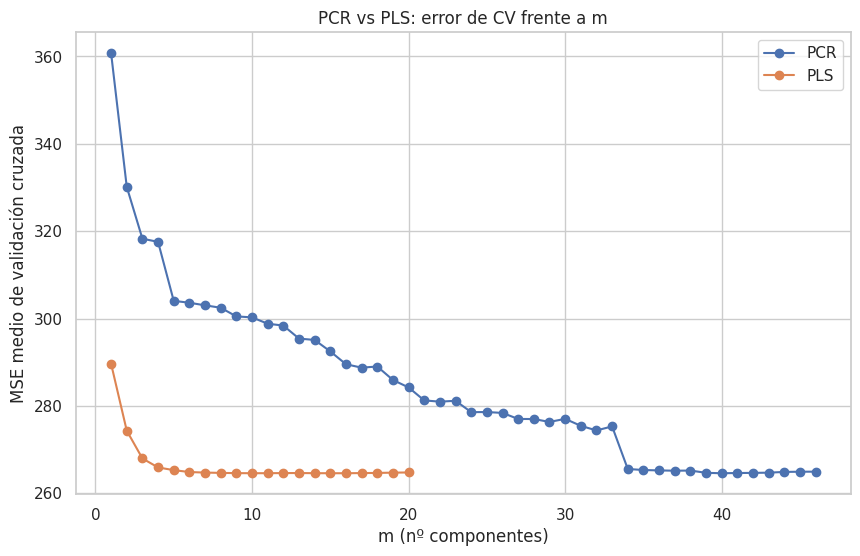

In [31]:
mses_pcr = -pcr_search.cv_results_["mean_test_score"]
mses_pls = -pls_search.cv_results_["mean_test_score"]

plt.plot(range(1, X_pen.shape[1] + 1), mses_pcr, marker="o", label="PCR")
plt.plot(range(1, n_pls + 1), mses_pls, marker="o", label="PLS")
plt.xlabel("m (nº componentes)"); plt.ylabel("MSE medio de validación cruzada")
plt.title("PCR vs PLS: error de CV frente a m")
plt.legend()
plt.show()

el eje horizontal es el número de componentes usadas para predecir y el vertical el error medio en validación cruzada (cuanto más bajo, mejor). **PLS** (supervisado) llega a su mínimo con pocas componentes (m = 16), mientras que **PCR** necesita muchas más (m = 40) para un error parecido. Por eso PLS es más eficiente aquí.


## 6. Regresión logística

### 6.1 Variable respuesta binaria

Se plantea un problema de **clasificación binaria**: predecir si una persona tiene **hipertensión diagnosticada** (`hypertension_dx`: `yes`/`no`). Es una variable binaria natural del dataset, así que no hace falta un segundo conjunto de datos.

> La **regresión logística** sirve para predecir un **sí/no** (aquí: "¿tiene hipertensión?"). En vez de dar un número, da una **probabilidad** (0 = seguro que no, 1 = seguro que sí) y luego decide: si la probabilidad supera 0.5, decimos "sí".

In [32]:
df["hypertension_dx"].value_counts(dropna=False)

hypertension_dx
no     6719
yes    4005
NaN      15
Name: count, dtype: int64

In [33]:
# Predictores: edad, IMC, sexo, colesterol total, HDL y tabaco
cols_log = ["hypertension_dx", "age", "bmi", "sex", "total_chol", "hdl", "smoking"]
d_log = df[cols_log].dropna()
d_log = d_log[d_log["hypertension_dx"].isin(["yes", "no"])].copy()
d_log["y"] = (d_log["hypertension_dx"] == "yes").astype(int)
d_log = pd.get_dummies(d_log, columns=["sex", "smoking"], drop_first=True)

feats = [c for c in d_log.columns if c not in ("hypertension_dx", "y")]
X_log = d_log[feats]
y_log = d_log["y"]

print("Observaciones:", d_log.shape[0], "| Prevalencia de hipertensión:", round(y_log.mean(), 3))

Observaciones: 9938 | Prevalencia de hipertensión: 0.372


### 6.2 Ajuste e interpretación (odds ratios)

> **Nota (asociación vs. predicción):** el modelo de esta sección (6.2) se ajusta sobre **todos los datos** (n = 9.938) y su objetivo es **interpretar asociaciones** mediante odds ratios. En la sección 6.3 se ajusta un **modelo distinto** con partición entrenamiento/test, cuyo objetivo es **evaluar la capacidad predictiva** (accuracy, AUC, matriz de confusión). Son dos objetivos —y dos modelos— distintos, no contradictorios.


> **¿Qué es una "odds" y un "odds ratio"?**
> - La **odds** es la relación "casos sí frente a casos no" (p. ej., 3 personas con hipertensión por cada 1 sin ella → odds = 3).
> - El **odds ratio (OR)** compara esa relación entre dos grupos. Un OR de 1.07 por año de edad significa "por cada año más, la odds de hipertensión se multiplica por 1.07". Regla práctica: **OR = 1** → no cambia; **OR > 1** → aumenta; **OR < 1** → disminuye. Y ojo: una odds **no** es lo mismo que una probabilidad.

In [ ]:
# statsmodels para interpretación (coeficientes y odds ratios)
#  Ajustamos un modelo que da, para cada persona, una probabilidad de tener
#    hipertensión. Luego convertimos los coeficientes a "odds ratios" (OR) para
#    leerlos de forma intuitiva (OR > 1 = aumenta, OR < 1 = disminuye, OR = 1 = nada).
X_log_const = sm.add_constant(X_log)
logit = sm.Logit(y_log, X_log_const).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 9938
Model:                          Logit   Df Residuals:                     9930
Method:                           MLE   Df Model:                            7
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.1893
Time:                        19:16:18   Log-Likelihood:                -5317.9
converged:                       True   LL-Null:                       -6559.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -5.1269      0.218    -23.485      0.000      -5.555      -4.699
age                0.0628      0.002     39.297      0.000       0.060       0.066
bmi                0.0716      0.004

In [35]:
odds = np.exp(logit.params)
print("Odds ratios (exp(β)):")
print(odds.round(3).to_string())

Odds ratios (exp(β)):
const             0.006
age               1.065
bmi               1.074
total_chol        0.998
hdl               0.998
sex_male          1.008
smoking_former    0.723
smoking_never     0.659


**Interpretación (asociación, no causalidad):**

- **`age`** (OR ≈ 1.07 por año): cada año adicional se asocia con una odds de hipertensión diagnosticada multiplicada por ~1.07 (≈ +90 % por década). Es el predictor con mayor asociación.
- **`bmi`** (OR ≈ 1.07 por unidad de IMC): un mayor IMC se **asocia** con mayores odds de hipertensión diagnosticada; al ser un modelo observacional, es una asociación y **no implica causalidad**.
- **`total_chol` y `hdl`** (OR ≈ 1.00): sin asociación apreciable con la odds de hipertensión diagnosticada en este modelo. No atribuimos este resultado a la medicación (p. ej., estatinas), ya que requeriría un análisis específico.
- **`smoking`:** no fumar se asocia a menor odds que fumar actualmente (OR ≈ 0.72 exfumador, ≈ 0.66 nunca fumador, tomando a los fumadores actuales como referencia).
- **`sex_male`** (OR ≈ 1.01): sin diferencias apreciables entre sexos tras ajustar por el resto.

*Nota:* el OR mide el cambio multiplicativo en la **odds** por unidad de la variable (manteniendo el resto constante), y una odds **no** equivale a una probabilidad: un OR de 1.07 no significa "7 % más de probabilidad".

### 6.3 Evaluación: matriz de confusión y medidas

> **Nota:** a diferencia de la sección 6.2 (modelo sobre todos los datos para interpretar asociaciones), aquí se entrena un modelo sobre el 80 % de los datos y se evalúa sobre el 20 % restante, con el objetivo de medir su **capacidad predictiva** sobre datos no vistos (accuracy, AUC, matriz de confusión).

In [ ]:
#  Entrenamos en el 80 % y evaluamos en el 20 % (estratificado: mantiene la
#    proporción de hipertensos en ambos lados).
X_tr, X_te, y_tr, y_te = train_test_split(
    X_log, y_log, test_size=0.2, random_state=RANDOM_STATE, stratify=y_log)

sc_log = StandardScaler().fit(X_tr)
lr = LogisticRegression(max_iter=1000).fit(sc_log.transform(X_tr), y_tr)

pred = lr.predict(sc_log.transform(X_te))
proba = lr.predict_proba(sc_log.transform(X_te))[:, 1]

cm = confusion_matrix(y_te, pred)
print("Matriz de confusión (filas = real, columnas = predicha):")
print(cm)
print()
print(f"Accuracy : {accuracy_score(y_te, pred):.3f}")
print(f"Precision: {precision_score(y_te, pred):.3f}")
print(f"Recall   : {recall_score(y_te, pred):.3f}")
print(f"F1-score : {f1_score(y_te, pred):.3f}")
print(f"AUC      : {roc_auc_score(y_te, proba):.3f}")

Matriz de confusión (filas = real, columnas = predicha):
[[1045  203]
 [ 321  419]]

Accuracy : 0.736
Precision: 0.674
Recall   : 0.566
F1-score : 0.615
AUC      : 0.803


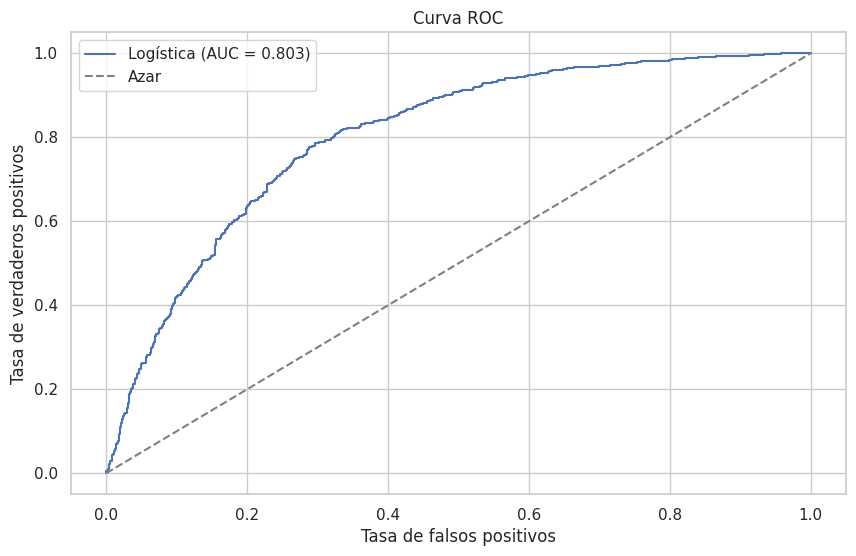

In [37]:
fpr, tpr, _ = roc_curve(y_te, proba)
plt.plot(fpr, tpr, label=f"Logística (AUC = {roc_auc_score(y_te, proba):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Azar")
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC")
plt.legend()
plt.show()

La curva ROC muestra el compromiso entre detectar a los verdaderos hipertensos (eje vertical, "aciertos") y disparar falsas alarmas (eje horizontal, "errores"). Cuanto más se acerque la curva a la esquina superior izquierda, mejor. La diagonal gris es lo que haría el azar. El **AUC** es el área bajo la curva: 0.5 = azar, 1.0 = perfecto; aquí ≈ 0.80, una discriminación razonable.


**Interpretación de la evaluación:** con esta partición, la regresión logística obtiene accuracy ≈ 0.74 y AUC ≈ 0.80. La matriz de confusión ([[1045, 203], [321, 419]]) muestra buena **especificidad** (≈ 0.84: se clasifican bien los "no hipertensos") pero un **recall** más bajo (≈ 0.57), es decir, se escapan más casos reales de hipertensión. El AUC ≈ 0.80 indica una capacidad discriminativa razonable.

> **Traducción de las medidas:**
> - **Accuracy (exactitud):** ¿qué porcentaje de respuestas acertamos en total? (~74 %).
> - **Recall (sensibilidad):** de las personas que SÍ tienen hipertensión, ¿a cuántas las detectamos? (~57 %). Aquí es donde más fallamos: se nos escapan casos reales.
> - **Especificidad:** de las que NO tienen hipertensión, ¿a cuántas las descartamos bien? (~84 %).
> - **AUC (~0.80):** mide si el modelo sabe *ordenar* a las personas por riesgo (0.5 = no mejor que el azar, 1.0 = perfecto). Un 0.80 es "razonablemente bueno".

In [38]:
# Efecto del umbral de decisión sobre recall y especificidad
# Con umbral 0.5 se escapan bastantes hipertensos; bajarlo detecta más casos
# a costa de más falsos positivos. Solo es ilustrativo: el umbral no se elige
# mirando el test.
filas = []
for t in [0.3, 0.4, 0.5, 0.6]:
    pred_t = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred_t).ravel()
    filas.append({"Umbral": t,
                  "Accuracy": accuracy_score(y_te, pred_t),
                  "Recall": tp / (tp + fn),
                  "Especificidad": tn / (tn + fp)})
display(pd.DataFrame(filas).round(3))

,Umbral,Accuracy,Recall,Especificidad
0,0.3,0.697,0.839,0.613
1,0.4,0.737,0.719,0.748
2,0.5,0.736,0.566,0.837
3,0.6,0.711,0.377,0.909


**Elección del umbral:** el umbral 0.5 es una convención, no una obligación. Bajarlo aumenta el **recall** (se detectan más hipertensos) pero reduce la **especificidad** (más falsas alarmas); subirlo hace lo contrario. Por ejemplo, con umbral 0.4 la accuracy se mantiene (≈ 0.74) pero el recall sube de ≈ 0.57 a ≈ 0.72, mientras la especificidad baja de ≈ 0.84 a ≈ 0.75. En un contexto de cribado clínico, donde dejar sin detectar a un hipertenso es más costoso que una falsa alarma, sería razonable usar un umbral más bajo. Para fijarlo de forma rigurosa habría que elegirlo con validación cruzada sobre el entrenamiento, no sobre el test; la tabla anterior solo ilustra el compromiso. El **AUC** no depende del umbral.

### 6.4 (Opcional) Comparación con LDA

In [39]:
lda = LinearDiscriminantAnalysis().fit(sc_log.transform(X_tr), y_tr)
pred_lda = lda.predict(sc_log.transform(X_te))
proba_lda = lda.predict_proba(sc_log.transform(X_te))[:, 1]

print("LDA:")
print(f"  Accuracy: {accuracy_score(y_te, pred_lda):.3f}")
print(f"  AUC     : {roc_auc_score(y_te, proba_lda):.3f}")

LDA:
  Accuracy: 0.737
  AUC     : 0.803


## 7. ¿Una o varias bases de datos?

Se ha utilizado **una única base de datos** (NHANES), ya que permite plantear razonablemente todos los problemas:

- **Regresión lineal:** `sbp` como respuesta cuantitativa.
- **Regularización:** panel de biomarcadores correlacionados.
- **PCA:** el mismo panel cuantitativo.
- **Regresión logística:** `hypertension_dx` como respuesta binaria (no ha sido necesario un segundo dataset).

A lo largo del trabajo, los modelos predictivos se han evaluado separando entrenamiento/test (20 % reservado para la evaluación final) y usando validación cruzada únicamente para **seleccionar hiperparámetros** (α de Ridge/Lasso, nº de componentes de PCR/PLS), nunca para la evaluación final.

## 8. Conclusiones

- **Relaciones encontradas:** la **edad** es el principal factor **asociado** a la presión arterial sistólica (`sbp ~ age + 0.49 mmHg/año`); el **IMC** también se asocia a una mayor presión (~0.39 mmHg por unidad). En la hipertensión, `age` y `bmi` son los predictores con mayor asociación (OR ≈ 1.07 por unidad/año). Se trata de asociaciones observacionales, no de relaciones causales.
- **Variables más relevantes:** `age` y `bmi` aparecen de forma consistente en regresión, Lasso y logística. Los biomarcadores adicionales añaden poca capacidad predictiva, pero conviene ser precisos: **Lasso conserva 42 de 46 variables**, de modo que su selección es limitada y **no** demuestra que el resto de biomarcadores carezcan de efecto independiente (pueden estar correlacionados con `age`/`bmi` o entre sí).
- **Diferencias entre modelos:** la diferencia de MSE en test entre OLS (≈ 236.5) y Ridge/Lasso (≈ 235.6–236.1) es pequeña y está dentro del ruido de una única partición de test, así que no cabe declarar un ganador claro; el valor de la regularización aquí es sobre todo de **estabilidad** ante la colinealidad. PLS alcanza el rendimiento de PCR con muchas menos componentes (16 frente a 40), al ser supervisado.
- **Qué aporta PCA:** resume los 46 biomarcadores, pero la reducción de dimensión es **moderada**: las 8 primeras componentes explican ~50.5 % y hacen falta ~15 para el 70 %, ~20 para el 80 % y ~27 para el 90 %. PC1 refleja el bloque del hemograma (`hemoglobin`, `hematocrit`, `mch`...) y PC2 una dimensión de adiposidad/síndrome metabólico, lo que muestra qué grupos de variables se mueven juntos y facilita interpretar la estructura de los datos.
- **Limitaciones:**
  - No se usan los **pesos muestrales** (`wt_mec`), por lo que no se pueden extrapolar prevalencias poblacionales.
  - Se **descartan** las filas con NA en vez de imputar (el análisis es con **casos completos**, por lo que el nº de observaciones cambia según los predictores), y se excluye la submuestra en ayunas.
  - **Medicación:** hipertensos/estatinas tienen la PA/colesterol tratados, lo que puede atenuar algunas asociaciones (no lo cuantificamos).
  - `age` está **top-coded a 80**, limitando el extremo superior.

Las conclusiones anteriores se derivan de los resultados obtenidos en las secciones previas.

> **Conclusión:** la **edad** y el **IMC** son los datos que mejor explican tanto la presión arterial como el riesgo de hipertensión; el resto de medidas añaden poca capacidad predictiva, y las técnicas "avanzadas" (Ridge, Lasso, PCA) confirman más que revolucionan los resultados — su valor es sobre todo dar **estabilidad** e **interpretación**.